# Tweet Sentiment Classification (Entity-level)

**Goal:** build a model that detects the sentiment (Negative / Neutral / Positive) of a tweet about a specific
entity (a game or a brand), so a marketing team can analyse customer opinion.

**Pipeline in this notebook**

| Step | What we do | Why |
|---|---|---|
| 1. Load data | Read the CSV and name the columns | The file has no header row |
| 2. Data cleaning | Handle missing values, duplicates, the `Irrelevant` class | Bad rows hurt the model |
| 3. EDA | Class balance, tweet length, entities | Understand the data before modelling |
| 4. Text preprocessing | Lowercase, remove URLs / numbers / symbols, emoticons, stopwords (keep negations) | Turn noisy tweets into clean tokens |
| 5. Text visuals | Top words and word clouds per sentiment | Sanity-check the signal |
| 6. Train/test split | Split **by tweet ID** | The dataset has paraphrases of each tweet; a random split leaks |
| 7. Text representation | TF-IDF with unigrams + bigrams | Convert text to numbers |
| 8. Models | Naive Bayes, Logistic Regression, Linear SVM | Compare simple, fast baselines |
| 9. Tuning | GridSearchCV on macro-F1 | Pick the best hyperparameters |
| 10. Evaluation | Classification report, confusion matrix, error analysis | See where the model fails |
| 11. Inference | Predict on new tweets | How the dashboard uses the model |

## 1. Imports and setup

In [1]:
import sys, warnings
sys.path.insert(0, ".")          # so we can import from src/ when running from the repo root
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 90)
SEED = 156

## 2. Load the data

The Kaggle file `twitter_training.csv` has **no header row**, so we name the columns ourselves:
`tweet_id`, `entity`, `sentiment`, `text`.

In [2]:
cols = ["tweet_id", "entity", "sentiment", "text"]
df = pd.read_csv("data/twitter_training.csv", header=None, names=cols)
df.shape

(74682, 4)

In [3]:
df.head()

,tweet_id,entity,sentiment,text
0,2401,Borderlands,Positive,"im getting on borderlands and i will murder you all ,"
1,2401,Borderlands,Positive,"I am coming to the borders and I will kill you all,"
2,2401,Borderlands,Positive,"im getting on borderlands and i will kill you all,"
3,2401,Borderlands,Positive,"im coming on borderlands and i will murder you all,"
4,2401,Borderlands,Positive,"im getting on borderlands 2 and i will murder you me all,"


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   tweet_id   74682 non-null  int64
 1   entity     74682 non-null  str  
 2   sentiment  74682 non-null  str  
 3   text       73996 non-null  str  
dtypes: int64(1), str(3)
memory usage: 11.4 MB


## 3. Data cleaning

### 3.1 Missing values
Text can't be filled with a mean, and filling with "Neutral" would invent labels. Missing text is a tiny share
of the data, so the simplest safe option is to **drop those rows**.

In [5]:
na = pd.DataFrame({"missing": df.isna().sum(), "percent": (df.isna().mean() * 100).round(2)})
na

,missing,percent
tweet_id,0,0.00
entity,0,0.00
sentiment,0,0.00
text,686,0.92


In [6]:
df = df.dropna(subset=["text"])
print("Missing values left:", df.isna().sum().sum())

Missing values left: 0


### 3.2 Duplicates
Rows that repeat the same values in all four columns add no information and can leak between train and test.

In [7]:
print("Duplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values("text").head()

Duplicate rows: 2340


,tweet_id,entity,sentiment,text
51504,10441,RedDeadRedemption(RDR),Negative,. . . Check out this clip! CGalvSports streaming Red Dead Redemption 2! clips.twitc...
51507,10441,RedDeadRedemption(RDR),Negative,. . . Check out this clip! CGalvSports streaming Red Dead Redemption 2! clips.twitc...
23580,4442,Google,Neutral,. - Android 9.0. . - Bezel-Less screen. . - Dolby Vision 4K display. . - DTS TruSurro...
23583,4442,Google,Neutral,. - Android 9.0. . - Bezel-Less screen. . - Dolby Vision 4K display. . - DTS TruSurro...
42270,10052,PlayerUnknownsBattlegrounds(PUBG),Neutral,. . pic.twitter.com/P1A5IeWDOa


In [8]:
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows after cleaning:", df.duplicated().sum(), "| rows left:", len(df))

Duplicate rows after cleaning: 0 | rows left: 71656


### 3.3 Label distribution
There are four labels. `Irrelevant` means the tweet is not about the entity.

In [9]:
counts = df["sentiment"].value_counts()
pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)})

,count,percent
sentiment,,
Negative,21698,30.3
Positive,19713,27.5
Neutral,17708,24.7
Irrelevant,12537,17.5


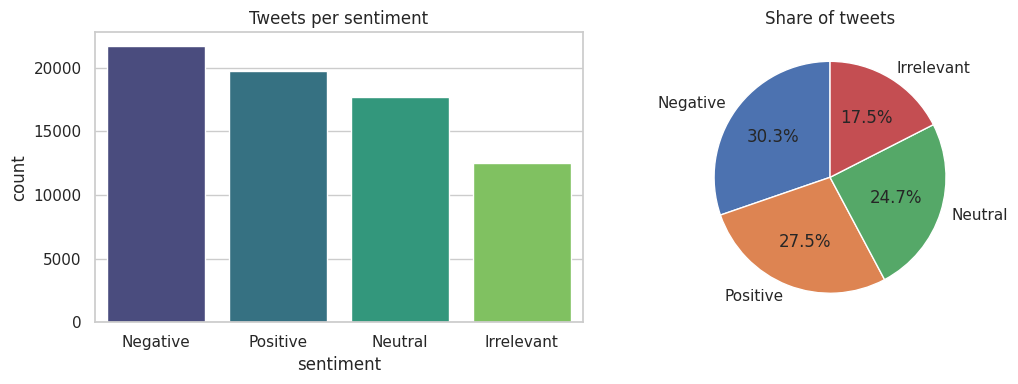

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="sentiment", order=counts.index, palette="viridis", ax=ax[0])
ax[0].set_title("Tweets per sentiment")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Share of tweets")
plt.tight_layout(); plt.show()

**Decision:** the three real sentiment classes are reasonably balanced (roughly 25-30% each), but `Irrelevant`
is a different kind of label and our client only wants sentiment on *relevant* tweets. We **drop `Irrelevant`**.

In [11]:
df = df[df["sentiment"] != "Irrelevant"].reset_index(drop=True)
df["sentiment"].value_counts()

sentiment
Negative    21698
Positive    19713
Neutral     17708
Name: count, dtype: int64

### 3.4 Encode labels
Models need numbers, not strings. `LabelEncoder` maps classes alphabetically.

In [12]:
from sklearn.preprocessing import LabelEncoder
enc = LabelEncoder()
df["label"] = enc.fit_transform(df["sentiment"])
print(dict(zip(enc.classes_, enc.transform(enc.classes_))))
df[["sentiment", "label"]].drop_duplicates().sort_values("label")

{'Negative': np.int64(0), 'Neutral': np.int64(1), 'Positive': np.int64(2)}


,sentiment,label
23,Negative,0
12,Neutral,1
0,Positive,2


## 4. Exploratory analysis

### 4.1 Tweet length

In [13]:
df["length"] = df["text"].str.len()
df[["text", "sentiment", "length"]].head()

,text,sentiment,length
0,"im getting on borderlands and i will murder you all ,",Positive,53
1,"I am coming to the borders and I will kill you all,",Positive,51
2,"im getting on borderlands and i will kill you all,",Positive,50
3,"im coming on borderlands and i will murder you all,",Positive,51
4,"im getting on borderlands 2 and i will murder you me all,",Positive,57


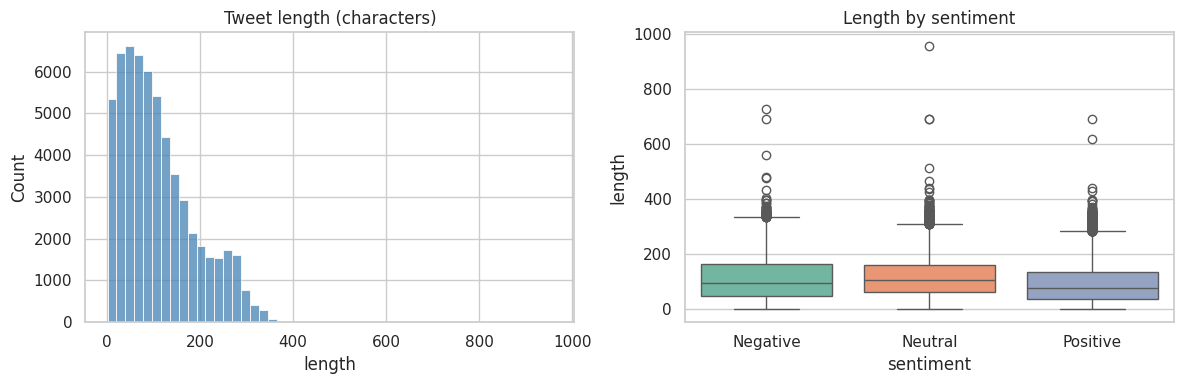

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
Negative,21698.0,113.4,81.7,1.0,48.0,94.0,163.0,727.0
Neutral,17708.0,119.6,77.3,1.0,63.0,106.0,162.0,957.0
Positive,19713.0,98.3,77.4,1.0,39.0,77.0,137.0,692.0


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["length"], bins=50, ax=ax[0], color="steelblue")
ax[0].set_title("Tweet length (characters)")
sns.boxplot(data=df, x="sentiment", y="length", order=enc.classes_, palette="Set2", ax=ax[1])
ax[1].set_title("Length by sentiment")
plt.tight_layout(); plt.show()
df.groupby("sentiment")["length"].describe().round(1)

### 4.2 Sentiment by entity

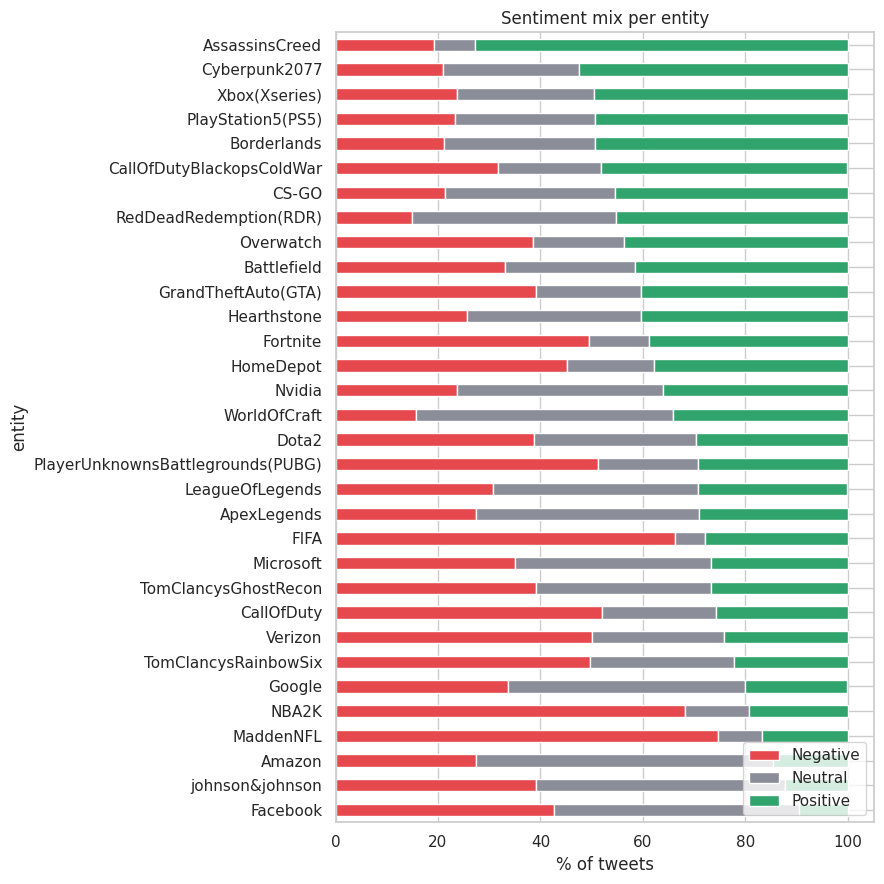

In [15]:
by_ent = pd.crosstab(df["entity"], df["sentiment"], normalize="index").mul(100).round(1)
by_ent.sort_values("Positive").plot(kind="barh", stacked=True, figsize=(9, 9),
                                    color=["#e5484d", "#8b8d98", "#30a46c"])
plt.xlabel("% of tweets"); plt.title("Sentiment mix per entity"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 5. Text preprocessing

Raw tweets are noisy. We clean them in these steps (the final function lives in `src/preprocess.py`
so the Streamlit app uses exactly the same logic):

1. Remove **URLs** and **@mentions**
2. Convert **emoticons** (`:)`, `:(`, `<3` ...) into words so the model can learn from them
3. **Lowercase** and remove numbers / punctuation / symbols
4. Remove **stopwords** (the, is, and ...) but **keep negations** (not, never, no): "not good" must stay different from "good"
5. Drop one-letter tokens

> Fix vs the original notebook: emoticons are converted **before** punctuation is removed. Otherwise the
> punctuation is already gone and the emoticon patterns can never match.

Let's walk through the steps on one sample tweet.

In [16]:
import re
from src.preprocess import URL_RE, MENTION_RE, EMOTICONS, NON_ALPHA_RE, STOPWORDS

sample = "@Nvidia I do NOT love this driver :( check https://t.co/xyz 100 times <3 Borderlands 2!!!"
print("0. raw           :", sample)
s = URL_RE.sub(" ", sample);      print("1. no URLs       :", s)
s = MENTION_RE.sub(" ", s);       print("2. no @mentions  :", s)
for pattern, repl in EMOTICONS:
    s = pattern.sub(repl, s)
print("3. emoticons     :", s)
s = NON_ALPHA_RE.sub(" ", s.lower()); print("4. lower, no nums:", s)
tokens = [w for w in s.split() if w not in STOPWORDS and len(w) > 1]
print("5. no stopwords  :", tokens)

0. raw           : @Nvidia I do NOT love this driver :( check https://t.co/xyz 100 times <3 Borderlands 2!!!
1. no URLs       : @Nvidia I do NOT love this driver :( check   100 times <3 Borderlands 2!!!
2. no @mentions  :   I do NOT love this driver :( check   100 times <3 Borderlands 2!!!
3. emoticons     :   I do NOT love this driver  sadface  check   100 times  heart  Borderlands 2!!!
4. lower, no nums:   i do not love this driver  sadface  check       times  heart  borderlands     
5. no stopwords  : ['not', 'love', 'driver', 'sadface', 'check', 'times', 'heart', 'borderlands']


In [17]:
from src.preprocess import clean_text
assert clean_text(sample) == " ".join(tokens)   # the packaged function gives the same result
clean_text(sample)

'not love driver sadface check times heart borderlands'

In [18]:
df["clean_text"] = df["text"].map(clean_text)
print("Rows that became empty after cleaning:", (df["clean_text"] == "").sum())
df = df[df["clean_text"] != ""].reset_index(drop=True)
df[["text", "clean_text", "sentiment"]].head(8)

Rows that became empty after cleaning: 1502


,text,clean_text,sentiment
0,"im getting on borderlands and i will murder you all ,",im getting borderlands murder,Positive
1,"I am coming to the borders and I will kill you all,",coming borders kill,Positive
2,"im getting on borderlands and i will kill you all,",im getting borderlands kill,Positive
3,"im coming on borderlands and i will murder you all,",im coming borderlands murder,Positive
4,"im getting on borderlands 2 and i will murder you me all,",im getting borderlands murder,Positive
5,"im getting into borderlands and i can murder you all,",im getting borderlands murder,Positive
6,So I spent a few hours making something for fun. . . If you don't know I am a HUGE @Bo...,spent hours making fun don know huge fan maya favorite characters decided make wallpap...,Positive
7,So I spent a couple of hours doing something for fun... If you don't know that I'm a h...,spent couple hours doing fun don know huge borderlands fan maya favorite characters de...,Positive


## 6. Text visuals

### 6.1 Most frequent words overall

In [19]:
def word_counts(series):
    return Counter(w for t in series for w in t.split())

all_counts = word_counts(df["clean_text"])
top = pd.DataFrame(all_counts.most_common(20), columns=["word", "freq"])
top.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
word,game,com,just,not,like,pic,twitter,play,johnson,new,no,good,really,time,love,unk,shit,people,amazon,don
freq,7796,7741,5496,5204,3856,3316,3160,3028,3004,2861,2827,2825,2685,2512,2502,2489,2222,2137,2063,1994


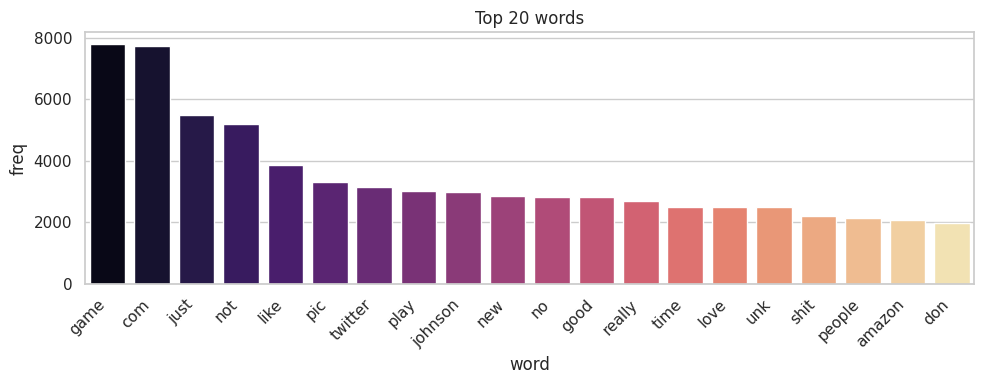

In [20]:
plt.figure(figsize=(10, 4))
sns.barplot(data=top, x="word", y="freq", palette="magma")
plt.xticks(rotation=45, ha="right"); plt.title("Top 20 words"); plt.tight_layout(); plt.show()

### 6.2 Word clouds: positive vs negative (top 50 words)
Generic words like *game*, *play* appear in every class, so on their own they carry little signal.

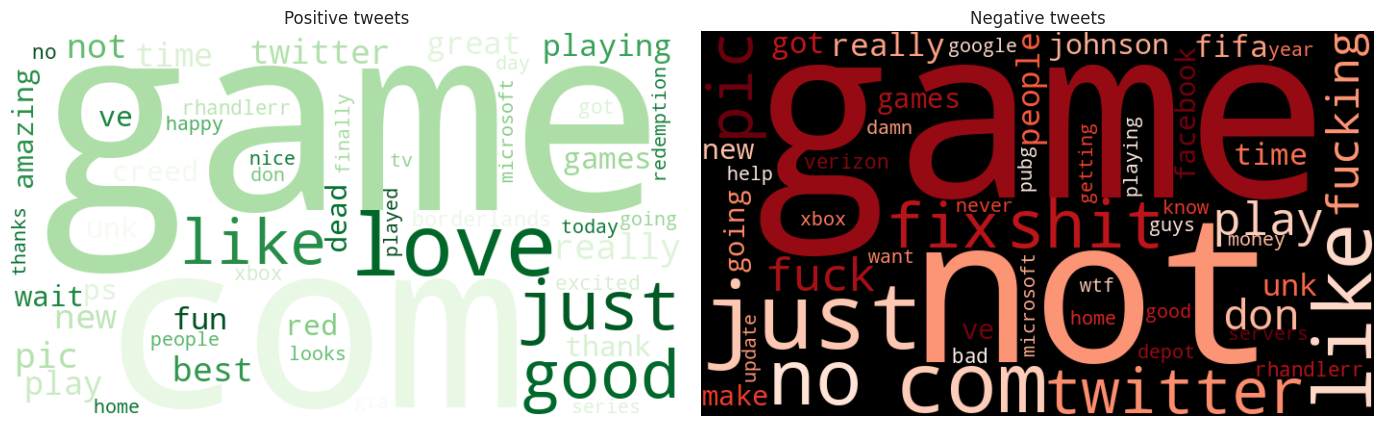

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, label, bg, cmap in zip(ax, ["Positive", "Negative"], ["white", "black"], ["Greens", "Reds"]):
    freq = dict(word_counts(df.loc[df["sentiment"] == label, "clean_text"]).most_common(50))
    a.imshow(WordCloud(width=700, height=400, background_color=bg, colormap=cmap)
             .generate_from_frequencies(freq), interpolation="bilinear")
    a.set_title(f"{label} tweets"); a.axis("off")
plt.tight_layout(); plt.show()

## 7. Train / test split

**Important detail:** each `tweet_id` appears 6 times in this dataset (paraphrases / near-copies of the same
tweet, always with the same label). If we split rows randomly, a tweet's paraphrase can land in the training set
while its sibling is in the test set, so the model just "remembers" it and the score looks great but means nothing.

We prove it below, then use a **group split by `tweet_id`**, so all copies of a tweet stay on the same side.

In [22]:
print("Rows per tweet_id:", df.groupby("tweet_id").size().value_counts().to_dict())
df[df["tweet_id"] == df["tweet_id"].iloc[0]][["tweet_id", "entity", "sentiment", "text"]]

Rows per tweet_id: {6: 7914, 5: 1355, 4: 668, 2: 216, 3: 76, 1: 26}


,tweet_id,entity,sentiment,text
0,2401,Borderlands,Positive,"im getting on borderlands and i will murder you all ,"
1,2401,Borderlands,Positive,"I am coming to the borders and I will kill you all,"
2,2401,Borderlands,Positive,"im getting on borderlands and i will kill you all,"
3,2401,Borderlands,Positive,"im coming on borderlands and i will murder you all,"
4,2401,Borderlands,Positive,"im getting on borderlands 2 and i will murder you me all,"
5,2401,Borderlands,Positive,"im getting into borderlands and i can murder you all,"


In [23]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

def quick_score(train_idx, test_idx):
    p = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                  ("clf", LinearSVC(C=0.5))])
    p.fit(df.loc[train_idx, "clean_text"], df.loc[train_idx, "label"])
    return accuracy_score(df.loc[test_idx, "label"], p.predict(df.loc[test_idx, "clean_text"]))

idx = np.arange(len(df))
r_tr, r_te = train_test_split(idx, test_size=0.3, stratify=df["label"], random_state=SEED)
g_tr, g_te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED)
                  .split(df, df["label"], groups=df["tweet_id"]))

print("tweet_ids shared by train and test (random split):", len(set(df.loc[r_tr, "tweet_id"]) & set(df.loc[r_te, "tweet_id"])))
print("tweet_ids shared by train and test (group split) :", len(set(df.loc[g_tr, "tweet_id"]) & set(df.loc[g_te, "tweet_id"])))
print(f"Accuracy with random split (leaky) : {quick_score(r_tr, r_te):.3f}")
print(f"Accuracy with group split (honest) : {quick_score(g_tr, g_te):.3f}")

tweet_ids shared by train and test (random split): 8734
tweet_ids shared by train and test (group split) : 0


Accuracy with random split (leaky) : 0.934


Accuracy with group split (honest) : 0.648


We continue with the **group split** (70% train / 30% test).

In [24]:
train_idx, test_idx = g_tr, g_te
X_train, y_train = df.loc[train_idx, "clean_text"], df.loc[train_idx, "label"]
X_test,  y_test  = df.loc[test_idx,  "clean_text"], df.loc[test_idx,  "label"]
print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])
pd.DataFrame({"train %": y_train.value_counts(normalize=True).sort_index().mul(100).round(1),
              "test %":  y_test.value_counts(normalize=True).sort_index().mul(100).round(1)}
             ).rename(index=dict(enumerate(enc.classes_)))

Train: 40241 | Test: 17376


,train %,test %
label,,
Negative,37.0,36.6
Neutral,30.0,29.7
Positive,33.1,33.7


## 8. Text representation: TF-IDF

**TF-IDF** gives each word a weight: high if it is frequent in a tweet but rare across all tweets.
We use **unigrams + bigrams** (`ngram_range=(1, 2)`) so phrases like *not good* become features, and
`min_df=2` to ignore words seen only once. The vectorizer is fitted on the **training set only** to avoid leakage.

In [25]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("Train matrix:", X_train_tfidf.shape, "| Test matrix:", X_test_tfidf.shape)
print("Non-zero entries (train):", X_train_tfidf.nnz,
      f"| sparsity: {1 - X_train_tfidf.nnz / np.prod(X_train_tfidf.shape):.4%}")
pd.Series(tfidf.get_feature_names_out()[:15], name="first features").to_frame().T

Train matrix: (40241, 75685) | Test matrix: (17376, 75685)
Non-zero entries (train): 682479 | sparsity: 99.9776%


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
first features,aaa,aaa game,aaa tietel,aaaaaaaaaaages,aaaaaaaaaaages worth,aahqxw,aahqxw cz,aajtak,aajtak zeenews,aamaavpjyc,aaron,aaron rivin,aaron rodgers,aat,aat try


## 9. Models

The original coursework used an RBF-kernel SVM, which is slow on thousands of TF-IDF features. TF-IDF data is
high-dimensional and mostly linear-separable, so **linear models** are fast *and* usually just as accurate.
We compare three:

| Model | Idea |
|---|---|
| **Complement Naive Bayes** | Fast probabilistic baseline made for text |
| **Logistic Regression** | Linear model with class probabilities |
| **Linear SVM (calibrated)** | Max-margin linear model; calibration adds probabilities for the dashboard |

**Metric:** we use **macro-F1**. For the client both false positives and false negatives matter, F1 balances
precision and recall, and *macro* averaging treats all three classes equally.

In [26]:
import time
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score

def make_pipe(clf, ngram=(1, 2)):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=ngram, min_df=2, sublinear_tf=True)), ("clf", clf)])

models = {
    "Complement Naive Bayes":  make_pipe(ComplementNB()),
    "Logistic Regression":     make_pipe(LogisticRegression(max_iter=1000, C=4)),
    "Linear SVM (calibrated)": make_pipe(CalibratedClassifierCV(LinearSVC(C=0.5), cv=3)),
}

rows, fitted = [], {}
for name, pipe in models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                 "macro_f1": f1_score(y_test, pred, average="macro"), "train_sec": round(time.time() - t0, 1)})
    fitted[name] = pipe

results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,macro_f1,train_sec
model,,,
Complement Naive Bayes,0.630,0.621,1.0
Logistic Regression,0.651,0.644,3.9
Linear SVM (calibrated),0.654,0.647,1.8


## 10. Hyperparameter tuning

We tune Logistic Regression with **GridSearchCV** (3-fold cross-validation, scoring = macro-F1):
regularisation strength `C` and the n-gram range. Because tweets from the same `tweet_id` are near-copies,
cross-validation must also respect the groups, so we pass `GroupKFold`.

In [27]:
from sklearn.model_selection import GridSearchCV, GroupKFold

grid = GridSearchCV(
    make_pipe(LogisticRegression(max_iter=1000)),
    param_grid={"clf__C": [1, 2, 4, 8, 16], "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)]},
    cv=GroupKFold(n_splits=3), scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train, groups=df.loc[train_idx, "tweet_id"])

print("Best params  :", grid.best_params_)
print(f"Best CV macro-F1: {grid.best_score_:.3f}")
cv = pd.DataFrame(grid.cv_results_)[["param_clf__C", "param_tfidf__ngram_range", "mean_test_score"]]
cv.sort_values("mean_test_score", ascending=False).head(6).round(3).reset_index(drop=True)

Best params  : {'clf__C': 1, 'tfidf__ngram_range': (1, 3)}
Best CV macro-F1: 0.631


,param_clf__C,param_tfidf__ngram_range,mean_test_score
0,1,"(1, 3)",0.631
1,1,"(1, 2)",0.631
2,2,"(1, 3)",0.628
3,2,"(1, 2)",0.626
4,4,"(1, 3)",0.624
5,4,"(1, 2)",0.622


In [28]:
tuned = grid.best_estimator_
pred = tuned.predict(X_test)
fitted["Logistic Regression (tuned)"] = tuned
results.loc["Logistic Regression (tuned)"] = [accuracy_score(y_test, pred),
                                              f1_score(y_test, pred, average="macro"), np.nan]
results.round(3).sort_values("macro_f1", ascending=False)

,accuracy,macro_f1,train_sec
model,,,
Logistic Regression (tuned),0.660,0.652,NaN
Linear SVM (calibrated),0.654,0.647,1.8
Logistic Regression,0.651,0.644,3.9
Complement Naive Bayes,0.630,0.621,1.0


## 11. Evaluation of the best model

We pick the model with the highest macro-F1 on the test set and look at per-class results.

In [29]:
best_name = results["macro_f1"].idxmax()
best = fitted[best_name]
y_pred = best.predict(X_test)
print("Best model:", best_name)
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=enc.classes_, digits=3))

Best model: Logistic Regression (tuned)
              precision    recall  f1-score   support

    Negative      0.672     0.759     0.713      6357
     Neutral      0.627     0.533     0.576      5156
    Positive      0.669     0.663     0.666      5863

    accuracy                          0.660     17376
   macro avg      0.656     0.652     0.652     17376
weighted avg      0.658     0.660     0.657     17376



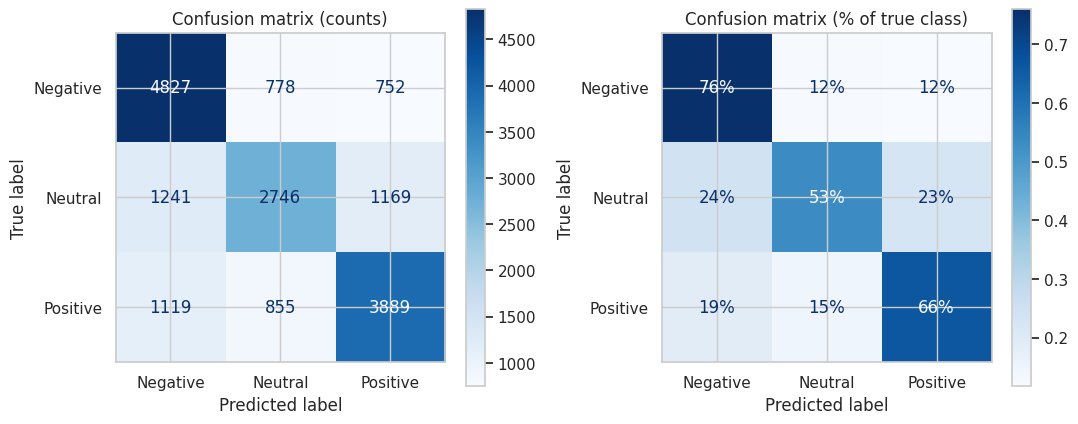

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=enc.classes_, cmap="Blues", ax=ax[0])
ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=enc.classes_, cmap="Blues",
                                        normalize="true", values_format=".0%", ax=ax[1])
ax[1].set_title("Confusion matrix (% of true class)")
plt.tight_layout(); plt.show()

**Reading the results**

- **Negative** is the easiest class (highest recall): complaints use distinctive words.
- **Neutral** is the hardest: neutral tweets share vocabulary with both other classes and often mention the
  entity without emotion.
- Typical errors confuse Neutral with Positive/Negative, which is expected for a bag-of-words model.

### 11.1 What did the model learn? (top words per class)

In [31]:
lr = make_pipe(LogisticRegression(max_iter=1000, C=4)).fit(X_train, y_train)
vocab = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coefs = lr.named_steps["clf"].coef_
top_words = pd.DataFrame({cls: vocab[np.argsort(coefs[i])[::-1][:12]] for i, cls in enumerate(enc.classes_)})
top_words

,Negative,Neutral,Positive
0,fix,com,best
1,servers,dlvr,excited
2,worst,tt,love
3,boring,check,thanks
4,problem,size,fun
5,fifa,amzn,thank
6,error,ly,nice
7,sucks,commission,dope
8,bullshit,just deserved,beautiful
9,shit,shit lol,cool


### 11.2 Error analysis: look at tweets the model got wrong

In [32]:
errors = df.loc[test_idx].copy()
errors["predicted"] = enc.inverse_transform(y_pred)
errors = errors[errors["sentiment"] != errors["predicted"]]
print(f"Misclassified: {len(errors)} of {len(test_idx)} ({len(errors)/len(test_idx):.1%})")
errors[["text", "sentiment", "predicted"]].sample(8, random_state=SEED).reset_index(drop=True)

Misclassified: 5914 of 17376 (34.0%)


,text,sentiment,predicted
0,.. We are pleased to sponsor @ springone this year! Join us for free and record some (...,Neutral,Negative
1,@DoT_India @rsprasad @GoI_MeitY @MTNLMbiOfficial Why in the world have you blocked,Negative,Positive
2,Good morning Kaballers Crew!.. Wow the support you all have shown is amazing! I was ta...,Neutral,Positive
3,Miss Daisy Pubg....,Negative,Positive
4,soon i can finally see melee again. it is just not the same when ice or leffen do not ...,Positive,Negative
5,They gone and have done it.,Positive,Negative
6,@ NBA you guys should continue the season on @ NBA2K and let the players play like the...,Neutral,Negative
7,"For me, the ghost of Tsushima is like a killer's credo...",Neutral,Negative


## 12. Predict on new tweets

This is exactly what the Streamlit dashboard does: clean the text, then call the pipeline.

In [33]:
new_tweets = [
    "I absolutely love the new Borderlands update, best patch ever!",
    "Servers are down again. Totally unacceptable, I want a refund.",
    "Just downloaded the game, will try it tonight.",
    "This is not good at all",
]
cleaned = [clean_text(t) for t in new_tweets]
proba = best.predict_proba(cleaned)
out = pd.DataFrame(proba, columns=enc.classes_).round(3)
out.insert(0, "tweet", new_tweets)
out["prediction"] = enc.inverse_transform(proba.argmax(1))
out

,tweet,Negative,Neutral,Positive,prediction
0,"I absolutely love the new Borderlands update, best patch ever!",0.024,0.041,0.935,Positive
1,"Servers are down again. Totally unacceptable, I want a refund.",0.962,0.013,0.025,Negative
2,"Just downloaded the game, will try it tonight.",0.187,0.159,0.654,Positive
3,This is not good at all,0.731,0.093,0.175,Negative


## 13. Conclusions and next steps

**What we built:** a cleaned dataset, a TF-IDF + linear model pipeline, honest evaluation (group split), and a
Streamlit dashboard (`streamlit run app.py`) that serves the model.

**Improvements over the original coursework notebook**
- Emoticon handling fixed and negations preserved
- Group-based split and group-based cross-validation to avoid leakage
- Faster models (seconds, not minutes) with comparable or better honest performance
- Reusable code in `src/`, `train.py`, and a deployable dashboard

**Possible next steps**
- Fine-tune a transformer (DistilBERT / RoBERTa) and compare with this baseline
- Add the entity as a feature
- Use class weights or threshold tuning to improve Neutral recall